## Persistence / Exceeding probability (PLCO & PROMISE)

[Baseline filter] 948 -> 919 clones (excluded clones already above threshold at first detection)

================ Persistence probability (PLCO) ================
[Persistence analysis] 2,054 below-threshold observations used: 919 clones from 353 participants


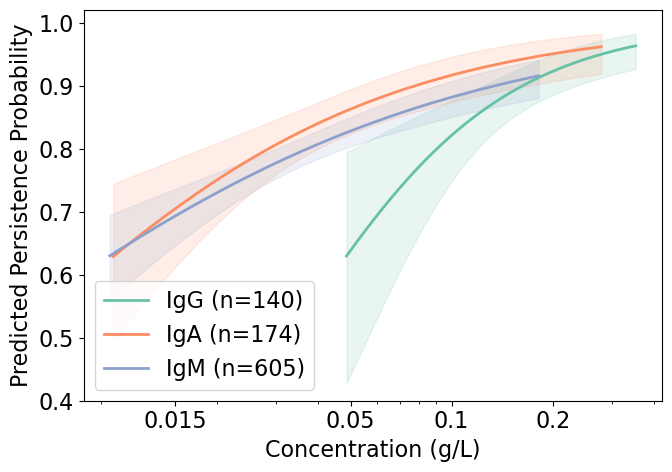


=== Persistence model summary (per isotype) ===
  isotype  n_obs  n_clones  events  coef_intercept  coef_slope    pval_slope  \
0     IgG    318       140     284        4.696178    1.377651  9.050284e-05   
1     IgA    412       174     346        4.250429    0.805121  1.382618e-05   
2     IgM   1324       605    1052        3.456720    0.629187  4.425571e-09   

  prob_cut  threshold_conc  
0     None             NaN  
1     None             NaN  
2     None             NaN  

=== Concentration where predicted persistence first reaches 80% ===
  isotype  prob_cut  min_observed_conc  prob_at_min_observed  \
0     IgG       0.8           0.048627              0.629655   
1     IgA       0.8           0.009812              0.628877   
2     IgM       0.8           0.009583              0.630048   

   already_met_at_min_observed  thr_point_estimate  thr_optimistic_upperCI  \
0                        False            0.090736                0.050939   
1                        False  

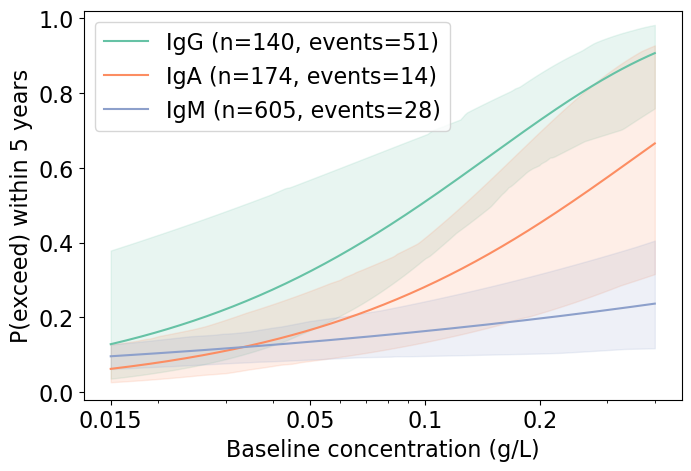

  Type_heavy  y_years  n_clones  events
0        IgG        5       140      51
1        IgA        5       174      14
2        IgM        5       605      28

=== Concentration where P(exceed within 5y) first reaches 20% ===
  isotype  prob_cut  min_observed_conc  prob_at_min_observed  \
0     IgG       0.2              0.015              0.128418   
1     IgA       0.2              0.015              0.062480   
2     IgM       0.2              0.015              0.096135   

   thr_point_estimate  thr_optimistic_upperCI  thr_conservative_lowerCI  
0            0.026445                0.015000                  0.059112  
1            0.063979                0.031390                  0.183730  
2            0.212410                0.059112                       NaN  
[PROMISE load] 4093 rows -> 3898 after QC; 1,269 participants, 3,050 clones
[Baseline filter] 804 -> 801 clones (excluded clones already above threshold at first detection)

================ Persistence probability (PROM

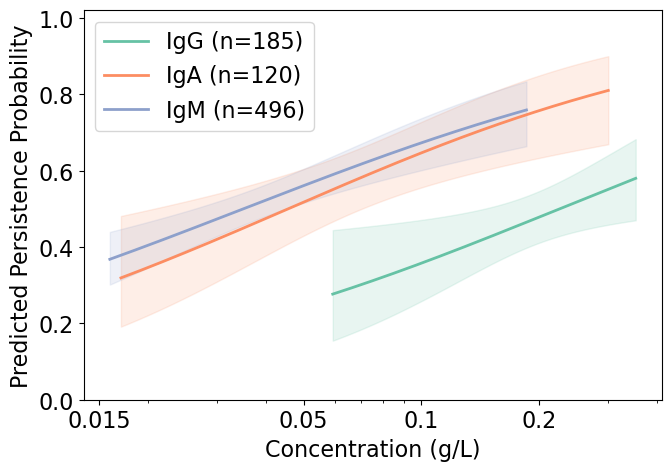


=== Persistence model summary (per isotype) ===
  isotype  n_obs  n_clones  events  coef_intercept  coef_slope  pval_slope  \
0     IgG    213       185     101        1.074263    0.720524    0.014964   
1     IgA    155       120      90        2.380341    0.770946    0.000621   
2     IgM    578       496     304        2.310303    0.689491    0.000001   

  prob_cut  threshold_conc  
0     None             NaN  
1     None             NaN  
2     None             NaN  

=== Concentration where predicted persistence first reaches 80% ===
  isotype  prob_cut  min_observed_conc  prob_at_min_observed  \
0     IgG       0.8            0.05936              0.276759   
1     IgA       0.8            0.01708              0.319235   
2     IgM       0.8            0.01600              0.367988   

   already_met_at_min_observed  thr_point_estimate  thr_optimistic_upperCI  \
0                        False                 NaN                     NaN   
1                        False          

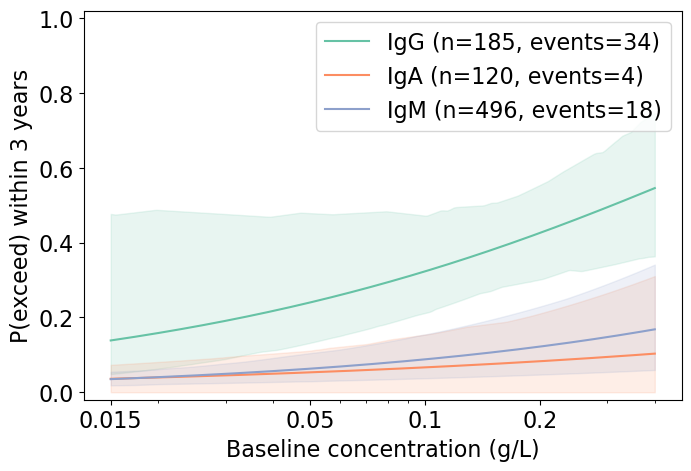

  Type_heavy  y_years  n_clones  events
0        IgG        3       185      34
1        IgA        3       120       4
2        IgM        3       496      18

=== Concentration where P(exceed within 3y) first reaches 20% ===
  isotype  prob_cut  min_observed_conc  prob_at_min_observed  \
0     IgG       0.2              0.015              0.138392   
1     IgA       0.2              0.015              0.035969   
2     IgM       0.2              0.015              0.035003   

   thr_point_estimate  thr_optimistic_upperCI  thr_conservative_lowerCI  
0            0.033529                0.015000                   0.09134  
1                 NaN                0.183730                       NaN  
2                 NaN                0.158922                       NaN  


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
import statsmodels.api as sm
import statsmodels.formula.api as smf
from lifelines import CoxPHFitter

BS_THRESHOLDS = {'IgG': 0.359, 'IgA': 0.325, 'IgM': 0.197}
ISOTYPE_ORDER = ['IgG', 'IgA', 'IgM']
PALETTE = {'IgG': '#66c2a5', 'IgA': '#fc8d62', 'IgM': '#8da0cb'}

# ------------------------- cohort configs --------------------------- #
PLCO_CFG = dict(person_col="e_2021_1015_id", clone_col="Clone_ID",
                time_col="Yr_before_dx", conc_col="Conc_1",
                iso_col="Type_heavy", age_col="age",
                time_ascending=False)

PROMISE_CFG = dict(person_col="PROMISE_ID", clone_col="clone_id",
                   time_col="yrs_from_baseline", conc_col="Conc",
                   iso_col="Heavy_type", age_col="age",
                   time_ascending=True)

def normalize_isotype(s):
    s = str(s)
    return next((k for k in BS_THRESHOLDS if k in s), np.nan)

# ------------------------------------------------------------------ #
# PROMISE loader (age from dob; QC filters)
# ------------------------------------------------------------------ #
ARTIFACT_FLAGS = ['<LLMI', 'MSL', 'MSL-Query', 'C1q-C', 'QDara', 'QDara, <LLMI']

def load_promise(path):
    df = pd.read_csv(path, sep=",")
    df['dob'] = pd.to_datetime(df['dob'], errors='coerce')
    df['Sample_Date'] = pd.to_datetime(df['Sample_Date'], errors='coerce')
    df['age'] = (df['Sample_Date'] - df['dob']).dt.days / 365.25
    df['Conc'] = pd.to_numeric(df['Conc'], errors='coerce')
    df['yrs_from_baseline'] = pd.to_numeric(df['yrs_from_baseline'], errors='coerce')

    n0 = len(df)
    remove_mask = (
        df['Remove_YN'].eq('Remove') |
        df['duplicate_sample_date'].eq('duplicate') |
        df['Flag'].isin(ARTIFACT_FLAGS)
    )
    df = df.loc[~remove_mask].copy()
    print(f"[PROMISE load] {n0} rows -> {len(df)} after QC; "
          f"{df['PROMISE_ID'].nunique():,} participants, "
          f"{df['clone_id'].nunique():,} clones")
    return df

# ------------------------------------------------------------------ #
# 1. Persistence intervals (works for both time directions)
# ------------------------------------------------------------------ #
def make_intervals(df, person_col, clone_col, time_col, conc_col,
                   time_ascending, **_):
    d = df.copy()
    d[conc_col] = pd.to_numeric(d[conc_col], errors='coerce')
    d["_detected"] = d[conc_col].fillna(0) > 0

    patient_timeline = (
        d.groupby(person_col)[time_col]
         .unique()
         .apply(lambda x: sorted(x, reverse=not time_ascending))
         .to_dict()
    )

    present_keys = set(
        d.loc[d[clone_col].notna() & d["_detected"], [person_col, time_col, clone_col]]
         .itertuples(index=False, name=None)
    )
    conc_map = (
        d.loc[d[clone_col].notna() & d["_detected"], [person_col, time_col, clone_col, conc_col]]
         .drop_duplicates([person_col, time_col, clone_col])
         .set_index([person_col, time_col, clone_col])[conc_col]
         .to_dict()
    )

    next_time_list, next_detected_list, next_conc_list = [], [], []
    for _, row in d.iterrows():
        pid, t, cl = row[person_col], row[time_col], row[clone_col]
        if pd.isna(cl):
            next_time_list.append(np.nan); next_detected_list.append(False); next_conc_list.append(np.nan)
            continue
        timeline = patient_timeline.get(pid, [])
        if t not in timeline:
            next_time_list.append(np.nan); next_detected_list.append(False); next_conc_list.append(np.nan)
            continue
        idx = timeline.index(t)
        found_time, found_detected, found_conc = np.nan, False, np.nan
        for future_t in timeline[idx + 1:]:
            key = (pid, future_t, cl)
            if key in present_keys:
                found_time, found_detected = future_t, True
                found_conc = conc_map.get(key, np.nan)
                break
        next_time_list.append(found_time)
        next_detected_list.append(found_detected)
        next_conc_list.append(found_conc)

    d["next_time"] = next_time_list
    d["next_detected"] = next_detected_list
    d["next_conc"] = next_conc_list
    d["y_persist"] = d["next_detected"].astype(int)

    # drop each participant's chronologically LAST visit (no future to check)
    last = d.groupby(person_col)[time_col].transform('max' if time_ascending else 'min')
    d = d[d[time_col] != last].copy()
    return d

# ------------------------------------------------------------------ #
# 2. Per-isotype logistic GLM (legend: n = unique clones, no events)
# ------------------------------------------------------------------ #
def logistic_glm_model_isotype(df, conc_col, outcome_col, isotype_col, clone_col,
                               use_log_conc=True, prob_cut=None,
                               min_events=10, min_total=30, grid_n=300,
                               x_ticks=(0.015, 0.05, 0.1, 0.2),
                               ylim=(0.4, 1.02), figsize=(7, 5),
                               robust_se=True, save_fig=None):
    plt.rcParams.update({'font.size': 16})
    d0 = df[[conc_col, outcome_col, isotype_col, clone_col]].dropna().copy()
    d0[conc_col] = pd.to_numeric(d0[conc_col], errors="coerce")
    d0[outcome_col] = pd.to_numeric(d0[outcome_col], errors="coerce").astype(int)
    d0[isotype_col] = d0[isotype_col].astype(str)
    d0 = d0.dropna(subset=[conc_col])
    d0 = d0[d0[conc_col] > 0].copy()

    loop_isotypes = [iso for iso in ISOTYPE_ORDER if iso in d0[isotype_col].unique()]

    plt.figure(figsize=figsize)
    rows, models, curves = [], {}, {}
    for iso in loop_isotypes:
        di = d0[d0[isotype_col] == iso].copy()
        n_obs = len(di)
        n_clones = di[clone_col].nunique()
        k = int(di[outcome_col].sum())
        if n_obs < min_total:
            print(f"[skip] {iso}: too few rows (n={n_obs})"); continue
        if k < min_events:
            print(f"[skip] {iso}: too few events (events={k})"); continue

        di["_x"] = np.log(di[conc_col].astype(float)) if use_log_conc else di[conc_col].astype(float)
        m = smf.glm(f"{outcome_col} ~ _x", data=di, family=sm.families.Binomial())
        res = m.fit(cov_type="HC1") if robust_se else m.fit()
        models[iso] = res
        b0, b1 = float(res.params["Intercept"]), float(res.params["_x"])
        pval1 = float(res.pvalues["_x"])

        xmin = max(float(np.nanquantile(di[conc_col], 0.01)), 1e-12)
        xmax = max(float(np.nanquantile(di[conc_col], 0.99)), xmin * 1.001)
        grid_c = np.geomspace(xmin, xmax, grid_n)
        new = pd.DataFrame({"_x": np.log(grid_c) if use_log_conc else grid_c})
        sf = res.get_prediction(new).summary_frame(alpha=0.05)
        p_hat = sf["mean"].to_numpy(float)
        lo = sf["mean_ci_lower"].to_numpy(float)
        hi = sf["mean_ci_upper"].to_numpy(float)
        curves[iso] = {"conc": grid_c, "p": p_hat, "lo": lo, "hi": hi,
                       "n_obs": n_obs, "n_clones": n_clones, "events": k,
                       "slope": b1, "pval_slope": pval1}

        # legend: clone count only (no events)
        plt.plot(grid_c, p_hat, lw=2, label=f"{iso} (n={n_clones:,})",
                 color=PALETTE.get(iso))
        plt.fill_between(grid_c, lo, hi, alpha=0.15, color=PALETTE.get(iso))

        thr = np.nan
        if prob_cut is not None and b1 > 0:
            logit_p = np.log(prob_cut / (1 - prob_cut))
            thr = float(np.exp((logit_p - b0) / b1)) if use_log_conc else float((logit_p - b0) / b1)
            plt.axhline(prob_cut, ls="--", alpha=0.25)
        rows.append({"isotype": iso, "n_obs": n_obs, "n_clones": n_clones, "events": k,
                     "coef_intercept": b0, "coef_slope": b1, "pval_slope": pval1,
                     "prob_cut": prob_cut, "threshold_conc": thr})

    plt.xscale("log")
    plt.xticks(list(x_ticks), [str(t) for t in x_ticks])
    plt.ylim(*ylim)
    plt.xlabel("Concentration (g/L)")
    plt.ylabel("Predicted Persistence Probability")
    plt.legend()
    plt.tight_layout()
    if save_fig: plt.savefig(save_fig, bbox_inches='tight')
    plt.show()
    return pd.DataFrame(rows).reset_index(drop=True), models, curves

def find_persist_threshold_range(curves, prob_cut=0.8):
    rows = []
    for iso, c in curves.items():
        conc, p, lo, hi = c["conc"], c["p"], c["lo"], c["hi"]
        def first_cross(arr):
            idx = np.where(arr >= prob_cut)[0]
            return float(conc[idx[0]]) if len(idx) else np.nan
        rows.append({"isotype": iso, "prob_cut": prob_cut,
                     "min_observed_conc": float(conc[0]),
                     "prob_at_min_observed": float(p[0]),
                     "already_met_at_min_observed": bool(p[0] >= prob_cut),
                     "thr_point_estimate": first_cross(p),
                     "thr_optimistic_upperCI": first_cross(hi),
                     "thr_conservative_lowerCI": first_cross(lo)})
    return pd.DataFrame(rows)

# ------------------------------------------------------------------ #
# 3. Cox: time from first detection to crossing MGUS (BS) threshold
# ------------------------------------------------------------------ #
def make_time_to_cross_df(df, person_col, clone_col, time_col, conc_col,
                          iso_col, age_col, time_ascending,
                          cross_level=0.2, threshold_mode='BS',
                          require_detected_at_baseline=True, **_):
    d = df[[person_col, clone_col, time_col, conc_col, iso_col, age_col]].copy()
    d = d.dropna(subset=[person_col, clone_col, time_col, conc_col, iso_col])
    d[conc_col] = d[conc_col].astype(float)
    d[time_col] = d[time_col].astype(float)
    d = d[d[conc_col] > 0]  

    # chronological order: first row of each clone = earliest observation
    d = d.sort_values([person_col, clone_col, time_col],
                      ascending=[True, True, time_ascending])

    rows = []
    for (pid, cid), g in d.groupby([person_col, clone_col], sort=False):
        base = g.iloc[0]
        base_time = float(base[time_col])
        base_conc = float(base[conc_col])
        iso = normalize_isotype(base[iso_col])

        if require_detected_at_baseline and base_conc <= 0:
            continue

        if threshold_mode == 'BS':
            current_thresh = BS_THRESHOLDS.get(iso, cross_level)
        else:
            current_thresh = cross_level

        age = float(g[age_col].dropna().iloc[0]) if g[age_col].notna().any() else np.nan

        crossed = g[g[conc_col] >= current_thresh]
        if len(crossed) > 0:
            event = 1
            t_end = float(crossed.iloc[0][time_col])
        else:
            event = 0
            t_end = float(g.iloc[-1][time_col])

        # elapsed time respects the clock direction
        t_years = (t_end - base_time) if time_ascending else (base_time - t_end)

        rows.append({"person_id": pid, "clone_id": cid, "Type_heavy": iso, "age": age,
                     "baseline_conc": base_conc,
                     "baseline_conc_log10": np.log10(max(base_conc, 1e-12)),
                     "t_years": float(t_years), "event_cross": int(event),
                     "threshold_used": current_thresh})
    out = pd.DataFrame(rows)
    out["t_years"] = out["t_years"].clip(lower=1e-6)
    return out

def fit_linear_cox_by_isotype(surv_df, penalizer=0.1, use_log_conc=True,
                              iso_col="Type_heavy", age_col="age",
                              conc_col="baseline_conc", time_col="t_years",
                              event_col="event_cross"):
    models = {}
    for iso in sorted(surv_df[iso_col].dropna().unique()):
        d = surv_df[surv_df[iso_col] == iso].dropna(subset=[time_col, event_col, conc_col, age_col]).copy()
        if d.empty or d[event_col].sum() == 0:
            continue
        d["_conc_x"] = np.log10(d[conc_col].astype(float)) if use_log_conc else d[conc_col].astype(float)
        mu_x, sd_x = float(d["_conc_x"].mean()), float(d["_conc_x"].std())
        mu_age, sd_age = float(d[age_col].mean()), float(d[age_col].std())
        fit_df = d[[time_col, event_col]].copy()
        fit_df["conc_z"] = (d["_conc_x"] - mu_x) / sd_x
        fit_df["age_z"] = (d[age_col] - mu_age) / sd_age
        cph = CoxPHFitter(penalizer=penalizer)
        cph.fit(fit_df, duration_col=time_col, event_col=event_col)
        # n = clones: the survival table has exactly one row per clone
        models[iso] = {"cph": cph, "use_log_conc": use_log_conc,
                       "mu_x": mu_x, "sd_x": sd_x, "mu_age": mu_age, "sd_age": sd_age,
                       "n": len(d), "events": int(d[event_col].sum())}
    return models

def predict_prob_within_y_linear(model, conc_raw_grid, y_horizon, age_value):
    cph = model["cph"]
    x = np.log10(np.clip(conc_raw_grid, 1e-12, None)) if model["use_log_conc"] else np.asarray(conc_raw_grid, float)
    z_x = (x - model["mu_x"]) / model["sd_x"]
    z_age = (age_value - model["mu_age"]) / model["sd_age"]
    X = pd.DataFrame({"conc_z": z_x, "age_z": z_age})
    S0 = cph.baseline_survival_
    t0 = S0.index[S0.index.get_indexer([y_horizon], method="nearest")[0]]
    S0_y = float(S0.loc[t0].values[0])
    linpred = X[["conc_z", "age_z"]].values @ cph.params_.reindex(["conc_z", "age_z"]).values
    return 1 - S0_y ** np.exp(linpred)

def bootstrap_exceeding_curve(surv_df_iso, iso, conc_grid, y_horizon, age_value,
                              n_boot=200, penalizer=0.1, use_log_conc=True, seed=1):
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        samp = surv_df_iso.sample(n=len(surv_df_iso), replace=True,
                                  random_state=int(rng.integers(1e9)))
        try:
            m = fit_linear_cox_by_isotype(samp, penalizer=penalizer, use_log_conc=use_log_conc)
            if iso not in m: continue
            boots.append(predict_prob_within_y_linear(m[iso], conc_grid, y_horizon, age_value))
        except Exception:
            continue
    if not boots:
        nanarr = np.full_like(conc_grid, np.nan, dtype=float)
        return nanarr, nanarr
    boots = np.array(boots)
    return np.nanpercentile(boots, 2.5, axis=0), np.nanpercentile(boots, 97.5, axis=0)

def plot_prob_curves_linear(models, surv_df, y_horizon=5.0, prob_cut=None,
                            save_fig=None, n_boot=200,
                            x_min=0.015, x_max=0.4,
                            x_ticks=(0.015, 0.05, 0.1, 0.2)):
    plt.rcParams.update({'font.size': 16})
    age_value = float(np.nanmedian(surv_df["age"]))
    conc_grid = np.logspace(np.log10(x_min), np.log10(x_max), 250)
    plt.figure(figsize=(7.2, 5.0))
    rows, curves = [], {}
    for iso in ISOTYPE_ORDER:
        if iso not in models: continue
        m = models[iso]
        p = predict_prob_within_y_linear(m, conc_grid, y_horizon, age_value)
        lo, hi = bootstrap_exceeding_curve(surv_df[surv_df["Type_heavy"] == iso], iso,
                                           conc_grid, y_horizon, age_value,
                                           n_boot=n_boot, use_log_conc=m["use_log_conc"])
        curves[iso] = {"conc": conc_grid, "p": p, "lo": lo, "hi": hi}
        # n = clones (one row per clone in the survival table)
        plt.plot(conc_grid, p, label=f"{iso} (n={m['n']:,}, events={m['events']})",
                 color=PALETTE.get(iso))
        plt.fill_between(conc_grid, lo, hi, alpha=0.15, color=PALETTE.get(iso))
        row = {"Type_heavy": iso, "y_years": y_horizon, "n_clones": m['n'], "events": m['events']}
        if prob_cut is not None:
            idx = np.where(p >= prob_cut)[0]
            row.update({"prob_cut": prob_cut,
                        "threshold_g_per_L": np.nan if len(idx) == 0 else float(conc_grid[idx[0]])})
        rows.append(row)
    plt.xscale("log")
    plt.ylim(-0.02, 1.02)
    plt.xticks(list(x_ticks), [str(t) for t in x_ticks])
    if prob_cut: plt.axhline(prob_cut, ls="--", alpha=0.25)
    plt.xlabel("Baseline concentration (g/L)")
    plt.ylabel(f"P(exceed) within {y_horizon} years")
    plt.legend()
    plt.tight_layout()
    if save_fig: plt.savefig(save_fig, bbox_inches='tight')
    plt.show()
    rows_df = pd.DataFrame(rows)
    print(rows_df)
    return rows_df, curves

def find_exceed_threshold_range(curves, prob_cut=0.2):
    rows = []
    for iso, c in curves.items():
        conc, p, lo, hi = c["conc"], c["p"], c["lo"], c["hi"]
        def first_cross(arr):
            idx = np.where(np.nan_to_num(arr, nan=-1) >= prob_cut)[0]
            return float(conc[idx[0]]) if len(idx) else np.nan
        rows.append({"isotype": iso, "prob_cut": prob_cut,
                     "min_observed_conc": float(conc[0]),
                     "prob_at_min_observed": float(p[0]),
                     "thr_point_estimate": first_cross(p),
                     "thr_optimistic_upperCI": first_cross(hi),
                     "thr_conservative_lowerCI": first_cross(lo)})
    return pd.DataFrame(rows)

# ------------------------------------------------------------------ #
# 4. One-call wrappers (cohort-agnostic)
# ------------------------------------------------------------------ #
def run_persistence(df, cfg, label="", ylim=(0.4, 1.02), prob_cut_report=0.80,
                    require_baseline_below=True,      
                    save_fig=None, **glm_kwargs):
    iso_col, conc_col = cfg['iso_col'], cfg['conc_col']
    clone_col, person_col = cfg['clone_col'], cfg['person_col']

    intervals = make_intervals(df, **cfg)
    intervals['_iso_norm'] = intervals[iso_col].apply(normalize_isotype)

    mgip = intervals[
        intervals['_iso_norm'].isin(ISOTYPE_ORDER) &
        (intervals[conc_col] > 0) &
        intervals.apply(lambda r: r[conc_col] < BS_THRESHOLDS.get(r['_iso_norm'], np.inf), axis=1)
    ].copy()

    if require_baseline_below:
        time_col, asc = cfg['time_col'], cfg['time_ascending']
        d0 = df[[clone_col, time_col, conc_col, iso_col]].copy()
        d0[conc_col] = pd.to_numeric(d0[conc_col], errors='coerce')
        d0 = d0[d0[conc_col] > 0]
        base = (d0.sort_values(time_col, ascending=asc)   # first row = earliest detection
                  .groupby(clone_col).first())
        base['_iso'] = base[iso_col].apply(normalize_isotype)
        base['_thr'] = base['_iso'].map(BS_THRESHOLDS)
        ok_clones = set(base.index[base[conc_col] < base['_thr'].fillna(np.inf)])
        before = mgip[clone_col].nunique()
        mgip = mgip[mgip[clone_col].isin(ok_clones)].copy()
        print(f"[Baseline filter] {before:,} -> {mgip[clone_col].nunique():,} clones "
              f"(excluded clones already above threshold at first detection)")
    
    print(f"\n================ Persistence probability {label} ================")
    print(f"[Persistence analysis] {len(mgip):,} below-threshold observations used: "
          f"{mgip[clone_col].nunique():,} clones from "
          f"{mgip[person_col].nunique():,} participants")

    summary, models, curves = logistic_glm_model_isotype(
        mgip, conc_col=conc_col, outcome_col='y_persist',
        isotype_col='_iso_norm', clone_col=clone_col,
        ylim=ylim, save_fig=save_fig, **glm_kwargs)
    print("\n=== Persistence model summary (per isotype) ===")
    print(summary)

    thr = find_persist_threshold_range(curves, prob_cut=prob_cut_report)
    print(f"\n=== Concentration where predicted persistence first reaches {prob_cut_report:.0%} ===")
    print(thr)
    return dict(intervals=intervals, mgip=mgip, summary=summary,
                models=models, curves=curves, threshold_table=thr)

def run_exceeding(df, cfg, label="", y_horizon=5, baseline_cut=0.2,
                  threshold_mode='BS', penalizer=0.1, n_boot=200,
                  restrict_to_clones=None,         
                  x_min=0.015, x_max=0.4, prob_cut_report=0.2, save_fig=None):
    surv = make_time_to_cross_df(df, **cfg, threshold_mode=threshold_mode)
    surv = surv[surv['Type_heavy'].isin(ISOTYPE_ORDER)]
    
    if baseline_cut == 'BS':
        mgip_surv = surv[surv['baseline_conc'] < surv['threshold_used']].copy()
        cut_desc = "isotype-specific clinical threshold"
    else:
        mgip_surv = surv[surv['baseline_conc'] < baseline_cut].copy()
        cut_desc = f"{baseline_cut} g/L"
        
    if restrict_to_clones is not None:
        before = mgip_surv['clone_id'].nunique()
        mgip_surv = mgip_surv[mgip_surv['clone_id'].isin(set(restrict_to_clones))].copy()
        print(f"[Restrict] {before:,} -> {mgip_surv['clone_id'].nunique():,} clones "
              f"(matched to the persistence analysis set)")
        
    print(f"\n================ Exceeding probability (Cox) {label} ================")
    print(f"[Cox input] {surv['clone_id'].nunique():,} clones with detected baseline from "
          f"{surv['person_id'].nunique():,} participants")
    print(f"[Cox analysis, baseline <{baseline_cut} g/L] "
          f"{mgip_surv['clone_id'].nunique():,} clones from "
          f"{mgip_surv['person_id'].nunique():,} participants "
          f"({int(mgip_surv['event_cross'].sum()):,} threshold-crossing events)")
    print(mgip_surv.groupby("Type_heavy").agg(
        n_clones=('clone_id', 'nunique'),
        n_participants=('person_id', 'nunique'),
        events=('event_cross', 'sum')))

    for y in [3, 5]:
        chk = mgip_surv.groupby("Type_heavy")["t_years"].agg(
            n="count",
            n_ge_y=lambda s, y=y: int((s >= y).sum()),
            frac_ge_y=lambda s, y=y: float((s >= y).mean()))
        print(f"-- follow-up >= {y}y --\n{chk}")

    models = fit_linear_cox_by_isotype(mgip_surv, penalizer=penalizer)
    for iso, m in models.items():
        print(f"[{iso}] n(clones)={m['n']}, events={m['events']}")

    rows_df, curves = plot_prob_curves_linear(
        models, mgip_surv, y_horizon=y_horizon, n_boot=n_boot,
        x_min=x_min, x_max=x_max, save_fig=save_fig)

    thr = find_exceed_threshold_range(curves, prob_cut=prob_cut_report)
    print(f"\n=== Concentration where P(exceed within {y_horizon}y) first reaches "
          f"{prob_cut_report:.0%} ===")
    print(thr)
    return dict(surv=surv, mgip_surv=mgip_surv, models=models,
                rows_df=rows_df, curves=curves, threshold_table=thr)

# ================================================================== #
# RUN: PLCO
# ================================================================== #
df_plco = pd.read_csv('../data/PLCO_ms_clone.csv', sep=",")

# persistence input: QC'd (same filters as before)
remove_mask = (
    (df_plco['Conc_1'].isna()) |
    (df_plco['Conc_1'] == 0) |
    (df_plco['Flag_1'].isin(['<LLMI', 'MSL', 'C1q-C'])) |
    (df_plco['Type_1'].isin(['Kappa', 'Lambda']))
)
df_plco_pers = df_plco.loc[~remove_mask].copy()

res_pers_plco = run_persistence(
    df_plco_pers, PLCO_CFG, label="(PLCO)",
    ylim=(0.4, 1.02),
    save_fig='../00.Figures/Persistence_Prob_PLCO_cases.pdf')

res_exc_plco = run_exceeding(
    df_plco_pers, PLCO_CFG, label="(PLCO)",
    y_horizon=5, baseline_cut='BS',
    restrict_to_clones=res_pers_plco['mgip'][PLCO_CFG['clone_col']].unique(), 
    save_fig='../00.Figures/Exceeding_Prob_PLCO_cases.pdf')

# ================================================================== #
# RUN: PROMISE
# ================================================================== #
df_prom = load_promise('../data/PROMISE_ms_clone.csv')

res_pers_prom = run_persistence(
    df_prom, PROMISE_CFG, label="(PROMISE)",
    ylim=(0.0, 1.02),
    save_fig='../00.Figures/Persistence_Prob_PROMISE.pdf')

res_exc_prom = run_exceeding(
    df_prom, PROMISE_CFG, label="(PROMISE)",
    y_horizon=3,   # PROMISE follow-up is shorter than PLCO
    baseline_cut='BS',
    restrict_to_clones=res_pers_prom['mgip'][PROMISE_CFG['clone_col']].unique(), 
    save_fig='../00.Figures/Exceeding_Prob_PROMISE.pdf')

## Distributional analysis to find concentration distinguish case (MM prog. & MGUS non-prog.) and controls (healthy) in PLCO

In [1]:
import pandas as pd
import numpy as np
import os, glob, subprocess, itertools
import matplotlib.pyplot as plt
import seaborn as sns
import colorcet as cc
import warnings
warnings.filterwarnings('ignore')
from matplotlib.ticker import FixedLocator, FuncFormatter
from sklearn.metrics import roc_curve, roc_auc_score
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

isotype_order = ['IgG', 'IgA', 'IgM']
thresholds = {'IgG': 0.359, 'IgA': 0.325, 'IgM': 0.197}
palette = {'IgG': '#66c2a5', 'IgA': '#fc8d62', 'IgM': '#8da0cb'}

################################## Prepare data ##################################

############## Controls
df = pd.read_csv('../data/PLCO_ms_healthy.csv', sep=",")

#### Set age
df['Age_At_Sample'] = df['age'] + (df['sample_drawdays']/365)

#### remove 'control' for MS run
df = df.dropna(subset=['plco_id'])

#### Those without hematopietic cancer
df = df[df['j_hema_cancer'] == 0]

#### Per clone (LATER)
ms_names = ['Type', 'm/z', 'Conc', 'Flag']
identifier_cols = [col for col in df.columns if not any(col.startswith(f"{n}_") for n in ms_names)]

reshaped = pd.wide_to_long(
    df, 
    stubnames=ms_names, 
    i=identifier_cols, 
    j='Sample_Nmber', 
    sep='_', 
    suffix='\d+'
).reset_index()

reshaped = reshaped.dropna(subset=['Type', 'Conc'], how='all')

reshaped['Conc'] = reshaped['Conc'].replace({"Present" : 0})
reshaped['Type_heavy'] = reshaped['Type'].str.split('_').str[0]

reshaped['Type_heavy'] = reshaped['Type_heavy'].astype(str) 
reshaped['Conc'] = pd.to_numeric(reshaped['Conc'], errors='coerce')

reshaped['log_Conc'] = np.log10(reshaped['Conc'])

#display(reshaped)

### Those with m.z positive
has_mz = (reshaped['m/z'].notna()) & (reshaped['Conc'].notna()) & (reshaped['Type'] != 'Lambda') & (reshaped['Type'] != 'Kappa')
df_mz_present = reshaped[has_mz].copy()    

### remove kappa and lambda
df_mz_present = df_mz_present[df_mz_present['Type_heavy'].isin(['IgG', 'IgA', 'IgM'])]

### Age clean
def clean_age(age_val):
    if pd.isna(age_val):
        return np.nan
    else:
        return int(age_val)

df_mz_present['Age_clean'] = df_mz_present['Age_At_Sample'].apply(clean_age)

############## Cases
filt_reshaped2 = pd.read_csv('../data/PLCO_ms_clone.csv', sep=",")

## remove <llmi and artifact
#filt_reshaped2 = filt_reshaped2[~filt_reshaped2['Flag_1'].isin(['<LLMI', 'C1q-C', 'MSL', 'MSL-Query'])]

def clean_age(age_val):
    if pd.isna(age_val):
        return np.nan
    else:
        return int(age_val)

filt_reshaped2['Age_clean'] = filt_reshaped2['Age_Sample'].apply(clean_age)

############# Numbers
### positive vs negative 
total_clones = len(reshaped)
## m/z and concentration present & no LC only
mz_present_count = has_mz.sum()
mz_absent_count = total_clones - mz_present_count

pos_df = reshaped[has_mz]
n_pos_samples = pos_df['plco_id'].nunique()
total_samples = reshaped['plco_id'].nunique()
n_neg_samples = total_samples - n_pos_samples

total_samples_case = filt_reshaped2['e_2021_1015_id'].nunique()
total_clones_case = filt_reshaped2['Clone_ID'].nunique()

print(f"PLCO Controls: Total N participant = {total_samples} (MS positive = {n_pos_samples}, No. of clone = {mz_present_count})")
print(f"PLCO Cases : Total N participant = {total_samples_case}, No. of clone = {total_clones_case}")

################################## Finding cutoff (Sensitivy analysis, ROC, bootstraping) ##################################
def find_best_threshold_bruteforce(df, isotype, llmi=0.015, thresholds=None):
    upper = thresholds.get(isotype, np.nan)

    sub = df[
        (df['Type_heavy'] == isotype) &
        (df['Conc_use'] >= llmi) &
        (df['Conc_use'] < upper)
    ].copy()

    n_case = (sub['group'] == 1).sum()
    n_control = (sub['group'] == 0).sum()

    if sub.empty or n_case == 0 or n_control == 0:
        return None

    #candidates = np.sort(sub['Conc_use'].dropna().unique())
    #candidates = np.linspace(llmi, upper, num=2000)
    candidates = np.logspace(np.log10(llmi), np.log10(upper), num=1000)

    best = None
    best_j = -np.inf

    for cutoff in candidates:
        pred_case = sub['Conc_use'] >= cutoff

        tp = ((sub['group'] == 1) & pred_case).sum()
        fn = ((sub['group'] == 1) & (~pred_case)).sum()
        tn = ((sub['group'] == 0) & (~pred_case)).sum()
        fp = ((sub['group'] == 0) & pred_case).sum()

        sens = tp / (tp + fn) if (tp + fn) > 0 else np.nan
        spec = tn / (tn + fp) if (tn + fp) > 0 else np.nan
        j = sens + spec - 1

        if j > best_j * 1.0001: #### if current J has very little difference with the maximum, choose lower cutoff
            best_j = j
            best = {
                'Type_heavy': isotype,
                'best_threshold': cutoff,
                'sensitivity': sens,
                'specificity': spec,
                'youden_j': j,
                'n_total': len(sub),
                'n_case': int(n_case),
                'n_control': int(n_control),
            }

    return best

def bootstrap_best_threshold_ci(
    df,
    isotype,
    llmi=0.015,
    thresholds=None,
    n_boot=100,
    ci=95,
    random_state=1
):
    rng = np.random.default_rng(random_state)

    upper = thresholds.get(isotype, np.nan)
    sub = df[
        (df['Type_heavy'] == isotype) &
        (df['Conc_use'] >= llmi) &
        (df['Conc_use'] < upper)
    ].copy()

    case_df = sub[sub['group'] == 1].copy()
    ctrl_df = sub[sub['group'] == 0].copy()

    if len(case_df) == 0 or len(ctrl_df) == 0:
        return None

    boot_thresholds = []
    boot_j = []

    for _ in range(n_boot):
        case_boot = case_df.sample(n=len(case_df), replace=True, random_state=rng.integers(1e9))
        ctrl_boot = ctrl_df.sample(n=len(ctrl_df), replace=True, random_state=rng.integers(1e9))
        boot_df = pd.concat([case_boot, ctrl_boot], ignore_index=True)

        res = find_best_threshold_bruteforce(
            boot_df,
            isotype=isotype,
            llmi=llmi,
            thresholds=thresholds
        )

        if res is not None and pd.notna(res['best_threshold']):
            boot_thresholds.append(res['best_threshold'])
            boot_j.append(res['youden_j'])

    if len(boot_thresholds) == 0:
        return None

    alpha = (100 - ci) / 2
    lo = np.percentile(boot_thresholds, alpha)
    hi = np.percentile(boot_thresholds, 100 - alpha)

    point = find_best_threshold_bruteforce(
        sub,
        isotype=isotype,
        llmi=llmi,
        thresholds=thresholds
    )

    out = {
        'Type_heavy': isotype,
        'point_threshold': point['best_threshold'],
        'threshold_ci_lower': lo,
        'threshold_ci_upper': hi,
        'ci_level': ci,
        'n_boot_valid': len(boot_thresholds),
        'median_boot_threshold': np.median(boot_thresholds),
        'boot_threshold_sd': np.std(boot_thresholds, ddof=1),
        'point_sensitivity': point['sensitivity'],
        'point_specificity': point['specificity'],
        'point_youden_j': point['youden_j'],
        'boot_thresholds': np.array(boot_thresholds),
        'boot_js': np.array(boot_j)
    }
    return out

##### Prepare inputs for defining lower limit (case vs control)
print("************************** Finding optimal threshold to distinguish cases vs controls **************************")

LLMI = 0.015

# control
control_df = df_mz_present.copy()
control_df = control_df.rename(columns={'Conc': 'Conc_use'})
control_df['group'] = 0   # control

# case
case_df = filt_reshaped2.copy()
case_df = case_df.rename(columns={'Conc_1': 'Conc_use'})
case_df['group'] = 1      # case

# select columns
common_cols = ['Type_heavy', 'Conc_use', 'group', 'Age_clean']
combined_df = pd.concat(
    [
        control_df[common_cols],
        case_df[common_cols]
    ],
    ignore_index=True
)

combined_df = combined_df.dropna(subset=['Type_heavy', 'Conc_use']).copy()
combined_df = combined_df[combined_df['Type_heavy'].isin(isotype_order)].copy()

boot_ci_results = {}

for age_cutoff in ['total', '<60', '>=60']:
    if age_cutoff == 'total':
        input_df = combined_df.copy()
    elif age_cutoff == '<60':
        input_df = combined_df[combined_df['Age_clean'] < 60]
    elif age_cutoff == '>=60':
        input_df = combined_df[combined_df['Age_clean'] >= 60]
    
    print(age_cutoff)
    
    boot_results = []
    boot_raw = {}

    for iso in isotype_order:
        out = bootstrap_best_threshold_ci(
            input_df,
            isotype=iso,
            llmi=0.015,
            thresholds=thresholds,
            n_boot=100,
            ci=95,
            random_state=42
        )
        if out is not None:
            boot_raw[iso] = out
            boot_results.append({
                'Type_heavy': out['Type_heavy'],
                'Best_threshold': out['point_threshold'],
                'CI_lower': out['threshold_ci_lower'],
                'CI_upper': out['threshold_ci_upper'],
                'Sensitivity': out['point_sensitivity'],
                'Specificity': out['point_specificity'],
                'Youden_J': out['point_youden_j'],
                'Boot_SD': out['boot_threshold_sd'],
                'n_boot_valid': out['n_boot_valid']
            })

    boot_ci_df = pd.DataFrame(boot_results)
    display(boot_ci_df.round(4))
    
    boot_ci_results[age_cutoff] = boot_ci_df.copy()


#### Use 'total'
boot_ci_total = boot_ci_results['total'].copy()

best_thr_map = dict(zip(boot_ci_total['Type_heavy'], boot_ci_total['Best_threshold']))
ci_lower_map = dict(zip(boot_ci_total['Type_heavy'], boot_ci_total['CI_lower']))
ci_upper_map = dict(zip(boot_ci_total['Type_heavy'], boot_ci_total['CI_upper']))

print(best_thr_map)
print(ci_lower_map)
print(ci_upper_map)


<frozen importlib._bootstrap>:219: RuntimeWarning: scipy._lib.messagestream.MessageStream size changed, may indicate binary incompatibility. Expected 56 from C header, got 64 from PyObject


PLCO Controls: Total N participant = 778 (MS positive = 661, No. of clone = 1224)
PLCO Cases : Total N participant = 491, No. of clone = 1885
************************** Finding optimal threshold to distinguish cases vs controls **************************
total


,Type_heavy,Best_threshold,CI_lower,CI_upper,Sensitivity,Specificity,Youden_J,Boot_SD,n_boot_valid
0,IgG,0.1262,0.1180,0.3545,0.7816,0.2381,0.0197,0.0848,100
1,IgA,0.0881,0.0709,0.1191,0.2467,0.8671,0.1137,0.0148,100
2,IgM,0.0441,0.0371,0.0870,0.4121,0.6702,0.0823,0.0126,100


<60


,Type_heavy,Best_threshold,CI_lower,CI_upper,Sensitivity,Specificity,Youden_J,Boot_SD,n_boot_valid
0,IgG,0.2731,0.1113,0.3390,0.2683,0.9375,0.2058,0.0404,100
1,IgA,0.1113,0.0220,0.2588,0.1231,0.9348,0.0579,0.0675,100
2,IgM,0.0972,0.0150,0.1782,0.1180,0.8956,0.0136,0.0556,100


>=60


,Type_heavy,Best_threshold,CI_lower,CI_upper,Sensitivity,Specificity,Youden_J,Boot_SD,n_boot_valid
0,IgG,0.1632,0.1151,0.3545,0.6193,0.4182,0.0375,0.0818,100
1,IgA,0.0881,0.0552,0.1191,0.2576,0.8819,0.1395,0.0160,100
2,IgM,0.0441,0.0390,0.0799,0.4269,0.6853,0.1122,0.0098,100


{'IgG': 0.126167719452276, 'IgA': 0.08809283100628428, 'IgM': 0.04405953851559696}
{'IgG': 0.11802124671685307, 'IgA': 0.07092648292794464, 'IgM': 0.03707095848732717}
{'IgG': 0.35446463683118296, 'IgA': 0.11911850430574301, 'IgM': 0.0870134687306597}


# 02. Validation using an indepdent healthy cohort

<frozen importlib._bootstrap>:219: RuntimeWarning: scipy._lib.messagestream.MessageStream size changed, may indicate binary incompatibility. Expected 56 from C header, got 64 from PyObject


Total N participant = 364
MS positive: N participant = 181, No. of clone = 301
MS negative: N participant = 183

Quartile Statistics (Age bin)


n  L_Whisker      Q1  Median      Q3  U_Whisker     Max
Type Age_Bin                                                           
IgG  <60       14     0.1690  0.2027  0.4361  1.0043     1.0491  8.5000
     60+       31     0.1096  0.1891  0.2817  0.4668     0.8662  4.9300
IgA  <60       12     0.0261  0.0312  0.0455  0.1154     0.0587  2.3200
     60+       25     0.0086  0.0487  0.0769  0.1250     0.2180  1.6100
IgM  <60      131     0.0049  0.0136  0.0237  0.0384     0.0738  0.8290
     60+       88     0.0018  0.0150  0.0208  0.0416     0.0698  0.4158

,Type_heavy,Age_Bin,n,BS_threshold,BS_threshold_percentile,Empirical_best_threshold,Empirical_best_percentile,CI_lower,CI_lower_percentile,CI_upper,CI_upper_percentile
0,IgG,<60,14,0.359,42.9,0.126,0.0,0.118,0.0,0.354,42.9
1,IgG,60+,31,0.359,64.5,0.126,6.5,0.118,6.5,0.354,64.5
2,IgA,<60,12,0.325,83.3,0.088,75.0,0.071,75.0,0.119,75.0
3,IgA,60+,25,0.325,92.0,0.088,60.0,0.071,44.0,0.119,64.0
4,IgM,<60,131,0.197,99.2,0.044,78.6,0.037,73.3,0.088,95.4
5,IgM,60+,88,0.197,96.6,0.044,76.1,0.037,70.5,0.088,92.0


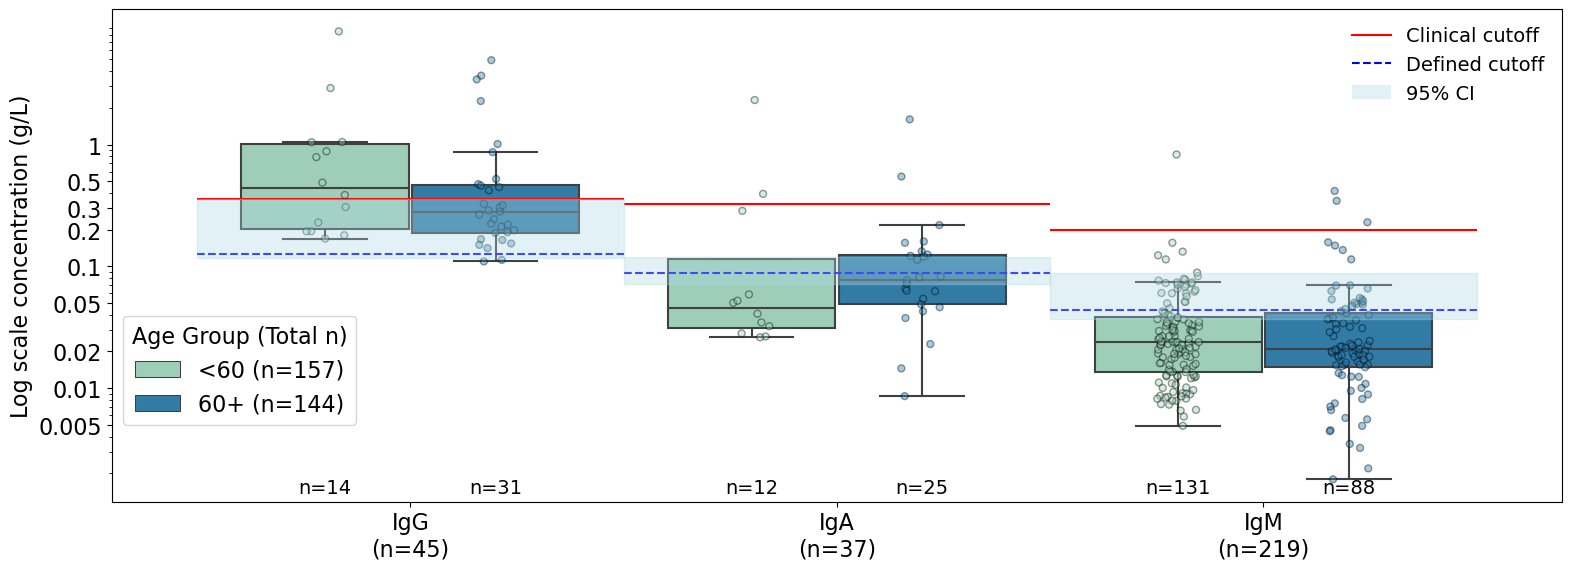

In [1]:
import pandas as pd
import numpy as np
import os, glob, subprocess, itertools
import matplotlib.pyplot as plt
import seaborn as sns
import colorcet as cc
import warnings
warnings.filterwarnings('ignore')
from matplotlib.ticker import FixedLocator, FuncFormatter
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

def percentile_position(series, value):
    series = series.dropna().sort_values()
    pct = (series <= value).sum() / len(series) * 100
    return pct

## from PLCO anlaysis
best_thr_map = {'IgG': 0.126, 'IgA': 0.088, 'IgM': 0.044}
ci_lower_map = {'IgG': 0.118, 'IgA': 0.071, 'IgM': 0.037}
ci_upper_map = {'IgG': 0.354, 'IgA': 0.119, 'IgM': 0.088}


df_name = '../data/external_healthy_ms.csv'

df = pd.read_csv(df_name, sep=",")

drop_cols = [col for col in df.columns if 'Flag 2' in col]
df = df.drop(columns=drop_cols)

drop_patterns = ['Flag Two', 'Flag 2', 'Comments', 'Unnamed']
drop_cols = [col for col in df.columns if any(p in col for p in drop_patterns)]
df = df.drop(columns=drop_cols)

if 'healthy' in df_name:
    df = df.drop_duplicates(subset=['Study ID'], keep='first')
    df['sample_id'] = df['Study ID']
elif 'infection' in df_name:
    df = df.drop_duplicates(subset=['Number '], keep='first')
    df['sample_id'] = df['Number ']

#### Rename
def rename_columns(cols):
    new_cols = []
    for col in cols:
        # Clone 
        if 'Clone' in col:
            num = col.split()[-1]
            new_cols.append(f'Type_{num}')
        # m/z 
        elif 'm/z' in col:
            num = '1' if '.' not in col else str(int(col.split('.')[-1]) + 1)
            new_cols.append(f'm.z_{num}')
        # g/L 
        elif 'g/L' in col and 'EXENT' not in col:
            num = '1' if '.' not in col else str(int(col.split('.')[-1]) + 1)
            new_cols.append(f'Conc_{num}')
        # Flag 
        elif 'Flag' in col:
            num = '1' if '.' not in col else str(int(col.split('.')[-1]) + 1)
            new_cols.append(f'Flag_{num}')
        else:
            new_cols.append(col)
    return new_cols

df.columns = rename_columns(df.columns)

ms_names = ['Type', 'm.z', 'Conc', 'Flag']
identifier_cols = [col for col in df.columns if not any(col.startswith(f"{n}_") for n in ms_names)]

reshaped = pd.wide_to_long(
    df, 
    stubnames=ms_names, 
    i=identifier_cols, 
    j='Clone_Number', 
    sep='_', 
    suffix='\d+'
).reset_index()

reshaped = reshaped.dropna(subset=['Type', 'Conc'], how='all')

reshaped['Conc'] = reshaped['Conc'].replace({"Present" : 0})
reshaped['Type_heavy'] = reshaped['Type'].str.split('_').str[0]

reshaped['Type_heavy'] = reshaped['Type_heavy'].astype(str) 
reshaped['Conc'] = pd.to_numeric(reshaped['Conc'], errors='coerce')

reshaped['log_Conc'] = np.log10(reshaped['Conc'])

#display(reshaped)

#### Flags
# <LLMI (below of quantification)
# C1q-C (artifact) --> no concentration
# MSL (mass shifted light chain due to glycosylation) --> no m/z ratio
# MSL-Query --> m/z ratio
# AIB (Antibody independent binding)

### positive vs negative 
total_clones = len(reshaped)
## m/z and concentration present & no LC only
has_mz = (reshaped['m.z'].notna()) & (reshaped['Conc'].notna()) & (reshaped['Type'] != 'Lambda') & (reshaped['Type'] != 'Kappa')
mz_present_count = has_mz.sum()
mz_absent_count = total_clones - mz_present_count

pos_df = reshaped[has_mz]
n_pos_samples = pos_df['sample_id'].nunique()
total_samples = reshaped['sample_id'].nunique()
n_neg_samples = total_samples - n_pos_samples

print(f"Total N participant = {total_samples}")
print(f"MS positive: N participant = {n_pos_samples}, No. of clone = {mz_present_count}")
print(f"MS negative: N participant = {n_neg_samples}")

#print(f"m.z Present: {mz_present_count} ({mz_present_count/total_clones*100:.1f}%)")
#print(f"m.z Absent: {mz_absent_count} ({mz_absent_count/total_clones*100:.1f}%)")

### Visualize concentration distribution     ### Those with m.z positive
df_mz_present = reshaped[has_mz].copy()    
#     df_mz_absent = reshaped[~has_mz].copy()
#     df_mz_absent['Conc'] = 0  

### remove kappa and lambda
df_mz_present = df_mz_present[df_mz_present['Type_heavy'].isin(['IgG', 'IgA', 'IgM'])]

isotype_order = ['IgG', 'IgA', 'IgM']
thresholds = {'IgG': 0.359, 'IgA': 0.325, 'IgM': 0.197}
palette = {'IgG': '#66c2a5', 'IgA': '#fc8d62', 'IgM': '#8da0cb'}

def get_boxplot_stats(df, group_col, value_col):
    stats_list = []
    for name, group in df.groupby(group_col):
        values = group[value_col].dropna()
        if values.empty: continue

        q1 = values.quantile(0.25)
        q2 = values.quantile(0.50) # Median
        q3 = values.quantile(0.75)
        iqr = q3 - q1

        # Whisker 
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr
        lower_whisker = values[values >= lower_bound].min()
        upper_whisker = values[values <= upper_bound].max()

        stats_list.append({
            'Type': name,
            'n': len(values),
            'Min': values.min(),
            'L_Whisker': lower_whisker,
            'Q1 (25%)': q1,
            'Median (50%)': q2,
            'Q3 (75%)': q3,
            'U_Whisker': upper_whisker,
            'Max': values.max()
        })
    return pd.DataFrame(stats_list).set_index('Type')


#################################### by age ####################################
def clean_age(age_val):
    if pd.isna(age_val):
        return np.nan
    age_str = str(age_val).strip()
    if '-' in age_str: ### for those as range --> get maximum
        age_str = age_str.split('-')[-1].strip()
    return int(age_str)

df_mz_present['Age_clean'] = df_mz_present['Age (years)'].apply(clean_age)

bin_configs = [
    #([0, 40, 50, 60, 70, 120], ['<40', '40-50', '50-60', '60-70', '70+']),
    #([0, 60, 70, 120], ['<60', '60-70', '70+']),
    ([0, 60, 120, ], ['<60', '60+', ])
]

for bins, labels in bin_configs:
    df_mz_present['age_bin'] = pd.cut(df_mz_present['Age_clean'], bins=bins, labels=labels)

    df_age_analysis = df_mz_present.dropna(subset=['age_bin'])

    def get_boxplot_stats_with_age(df, group_cols, value_col):
        stats_list = []
        for names, group in df.groupby(group_cols):
            values = group[value_col].dropna()
            if values.empty: continue

            q1 = values.quantile(0.25)
            q2 = values.quantile(0.50)
            q3 = values.quantile(0.75)
            iqr = q3 - q1

            lower_whisker = values[values >= (q1 - 1.5 * iqr)].min()
            upper_whisker = values[values <= (q3 + 1.5 * iqr)].max()

            stats_list.append({
                'Type': names[0],
                'Age_Bin': names[1],
                'n': len(values),
                'L_Whisker': lower_whisker,
                'Q1': q1,
                'Median': q2,
                'Q3': q3,
                'U_Whisker': upper_whisker,
                'Max': values.max()
            })
        return pd.DataFrame(stats_list)

    print(f"\nQuartile Statistics (Age bin)")
    age_stats = get_boxplot_stats_with_age(df_mz_present, ['Type_heavy', 'age_bin'], 'Conc')
    age_stats['Type'] = pd.Categorical(age_stats['Type'], categories=isotype_order, ordered=True)
    age_stats['Age_Bin'] = pd.Categorical(age_stats['Age_Bin'], categories=labels, ordered=True)
    age_stats = age_stats.sort_values(['Type', 'Age_Bin']).set_index(['Type', 'Age_Bin'])

    display(age_stats.round(4))

    plt.rcParams.update({
        'font.size': 16,         
        'axes.labelsize': 16,     
        'xtick.labelsize': 16,    
        'ytick.labelsize': 16,
        'legend.fontsize': 16     
    })
    plt.figure(figsize=(16, 6))

    ax2 = sns.boxplot(data=df_age_analysis, x='Type_heavy', y='Conc', 
                      hue='age_bin', order=isotype_order, 
                      palette="YlGnBu", showfliers=False)

    sns.stripplot(data=df_age_analysis, x='Type_heavy', y='Conc', 
                  hue='age_bin', order=isotype_order,
                  linewidth=1, edgecolor='black',
                  dodge=True, alpha=0.4, palette="YlGnBu", ax=ax2)

    handles, labels_legend = ax2.get_legend_handles_labels()
    ax2.legend(handles[0:len(labels)], labels_legend[0:len(labels)], 
               title='Age Group', loc='upper right')

    for i, isotype in enumerate(isotype_order):
        bs_val = thresholds.get(isotype, np.nan)
        ci_lo = ci_lower_map.get(isotype, np.nan)
        best_thr = best_thr_map.get(isotype, np.nan)
        ci_hi = ci_upper_map.get(isotype, np.nan)

        c = palette.get(isotype, "black")  
        # BS threshold
        if bs_val is not None:
            ax2.hlines(y=bs_val, xmin=i-0.5, xmax=i+0.5,
                       #colors=c, 
                       colors='red',
                       linestyle='-', linewidth=1.5)
#                 ax2.text(i+0.42, bs_val, f'Clinial cutoff {bs_val:.3f}',
#                          va='center', color=c, fontweight='bold', fontsize=9)

        # empirical lower / best / upper
        if pd.notna(ci_lo) and pd.notna(ci_hi):
            ax2.fill_between(
                [i-0.5, i+0.5],
                ci_lo,
                ci_hi,
                #color=c,
                color='lightblue',
                alpha=0.35,
                zorder=5
            )

        # best threshold line
        if pd.notna(best_thr):
            ax2.hlines(
                y=best_thr,
                xmin=i-0.5,
                xmax=i+0.5,
                #colors=c,
                colors='blue',
                linestyle='--',
                linewidth=1.5
            )


    legend_elements = [
        Line2D(
            [0], [0],
            color='red',
            linestyle='-',
            linewidth=1.5,
            label='Clinical cutoff'
        ),

        Line2D(
            [0], [0],
            color='blue',
            linestyle='--',
            linewidth=1.5,
            label='Defined cutoff'
        ),

        Patch(
            facecolor='lightblue',
            alpha=0.35,
            label='95% CI'
        )
    ]

    leg1 = ax2.legend(
        handles=legend_elements,
        loc='upper right',
        frameon=False,
        fontsize=14
    )
    ax2.add_artist(leg1) 

    yticks = [0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 1.0]
    ax2.set_yscale('log')
    ax2.yaxis.set_major_locator(FixedLocator(yticks))
    ax2.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:g}"))

    ### Numbers
    type_counts = df_age_analysis['Type_heavy'].value_counts()
    age_counts = df_age_analysis['age_bin'].value_counts()

    # X-axis N
    new_xticklabels = [f"{iso}\n(n={type_counts.get(iso, 0)})" for iso in isotype_order]
    ax2.set_xticklabels(new_xticklabels)

    # Age group N
    handles, _ = ax2.get_legend_handles_labels() 

    new_legend_labels = [f"{age_l} (n={age_counts.get(age_l, 0)})" for age_l in labels]

    ax2.legend(handles[:len(labels)], new_legend_labels, 
               title='Age Group (Total n)', 
               bbox_to_anchor=(0, 0.4), loc='upper left')

    ### N for each group
    counts = (
        df_age_analysis
        .groupby(['Type_heavy', 'age_bin'])
        .size()
        .reset_index(name='n')
    )

    ymin, ymax = ax2.get_ylim()
    y_text = ymin * 1.1  

    n_hue = len(labels)
    width = 0.8  
    step = width / n_hue
    offsets = np.linspace(-width/2 + step/2, width/2 - step/2, n_hue)

    percentile_rows = []

    for i, iso in enumerate(isotype_order):
        for j, age_l in enumerate(labels):
            n_val = counts.loc[
                (counts['Type_heavy'] == iso) & (counts['age_bin'] == age_l), 'n'
            ]
            if len(n_val) == 0:
                continue

            x_pos = i + offsets[j]
            ax2.text(
                x_pos, y_text,
                f"n={int(n_val.values[0])}",
                ha='center', va='bottom', fontsize=14
            )


    ### Print percentile by age bin
    percentile_rows = []

    for iso in isotype_order:
        for age_l in labels:
            values = df_age_analysis.loc[
                (df_age_analysis['Type_heavy'] == iso) &
                (df_age_analysis['age_bin'] == age_l),
                'Conc'
            ].dropna()

            if len(values) == 0:
                continue

            thresh = thresholds.get(iso, np.nan)
            best_thr = best_thr_map.get(iso, np.nan)
            ci_lo = ci_lower_map.get(iso, np.nan)
            ci_hi = ci_upper_map.get(iso, np.nan)

            percentile_rows.append({
                'Type_heavy': iso,
                'Age_Bin': age_l,
                'n': len(values),

                'BS_threshold': thresh,
                'BS_threshold_percentile': f"{percentile_position(values, thresh):.1f}",

                'Empirical_best_threshold': best_thr,
                'Empirical_best_percentile': f"{percentile_position(values, best_thr):.1f}" if pd.notna(best_thr) else np.nan,

                'CI_lower': ci_lo,
                'CI_lower_percentile': f"{percentile_position(values, ci_lo):.1f}" if pd.notna(ci_lo) else np.nan,

                'CI_upper': ci_hi,
                'CI_upper_percentile': f"{percentile_position(values, ci_hi):.1f}" if pd.notna(ci_hi) else np.nan,

            })

    percentile_df = pd.DataFrame(percentile_rows)

    percentile_df['Type_heavy'] = pd.Categorical(
        percentile_df['Type_heavy'],
        categories=isotype_order,
        ordered=True
    )
    percentile_df['Age_Bin'] = pd.Categorical(
        percentile_df['Age_Bin'],
        categories=labels,
        ordered=True
    )

    percentile_df = percentile_df.sort_values(['Type_heavy', 'Age_Bin']).reset_index(drop=True)

    display(percentile_df)



    plt.ylabel('Log scale concentration (g/L)')
    plt.xlabel('')
    plt.tight_layout()
    plt.savefig(f'../00.Figures/Distribution_Mprotein_age_Healthy.pdf', bbox_inches='tight')
    plt.show()